In [1]:
import os
import sys
import argparse
from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image
import time

In [ ]:

class ObjectDetector:
    def __init__(self, model_path, conf_threshold=0.25, iou_threshold=0.45):
        self.model_path = model_path
        self.conf_threshold = conf_threshold
        self.iou_threshold = iou_threshold
        self.model = YOLO(model_path)
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.class_names = {0: 'person', 1: 'pet'}
        self.class_colors = {
            'person': (255, 0, 0),
            'pet': (0, 255, 0)
        }
        print(f"Loaded model: {model_path} on {self.device}")

    def detect_objects(self, image_path):
        image = cv2.imread(image_path)
        if image is None:
            raise ValueError(f"Could not read image from {image_path}")
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        start_time = time.time()
        results = self.model(image_rgb, conf=self.conf_threshold, iou=self.iou_threshold, device=self.device)
        inference_time = time.time() - start_time
        return results[0], inference_time

    def draw_detections(self, image, detections):
        annotated_image = image.copy()
        if detections.boxes is not None:
            boxes = detections.boxes
            for i in range(len(boxes)):
                x1, y1, x2, y2 = boxes.xyxy[i].cpu().numpy().astype(int)
                class_id = int(boxes.cls[i])
                confidence = float(boxes.conf[i])
                class_name = self.class_names.get(class_id, f"class_{class_id}")
                color = self.class_colors.get(class_name, (0, 0, 255))
                cv2.rectangle(annotated_image, (x1, y1), (x2, y2), color, 2)
                label = f"{class_name}: {confidence:.2f}"
                (lw, lh), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 2)
                cv2.rectangle(annotated_image, (x1, y1 - lh - 10), (x1 + lw, y1), color, -1)
                cv2.putText(annotated_image, label, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 2)
        return annotated_image

    def get_detection_stats(self, detections):
        stats = {
            'total_detections': 0,
            'person_count': 0,
            'pet_count': 0,
            'avg_confidence': 0,
            'detections': []
        }
        if detections.boxes is not None:
            boxes = detections.boxes
            stats['total_detections'] = len(boxes)
            confidences = []
            for i in range(len(boxes)):
                class_id = int(boxes.cls[i])
                confidence = float(boxes.conf[i])
                x1, y1, x2, y2 = boxes.xyxy[i].cpu().numpy()
                class_name = self.class_names.get(class_id, f"class_{class_id}")
                if class_name == 'person':
                    stats['person_count'] += 1
                elif class_name == 'pet':
                    stats['pet_count'] += 1
                confidences.append(confidence)
                stats['detections'].append({
                    'class': class_name,
                    'confidence': confidence,
                    'bbox': [float(x1), float(y1), float(x2), float(y2)],
                    'area': float((x2 - x1) * (y2 - y1))
                })
            if confidences:
                stats['avg_confidence'] = np.mean(confidences)
        return stats


In [24]:
def run_single_image(detector, image_path, output_path=None, show=True):
    """
    Runs object detection on a single image and displays results.

    Args:
        detector (ObjectDetector): The initialized detector.
        image_path (str): Path to the input image.
        output_path (str, optional): If set, saves the annotated image.
        show (bool, optional): If True, displays the result.

    Returns:
        annotated (np.ndarray): Annotated image with drawn detections.
        stats (dict): Detection statistics.
    """
    print(f"\nRunning inference on: {image_path}")
    
    # Load image
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError(f"Image not found at path: {image_path}")
    
    # Run detection
    detections, inference_time = detector.detect_objects(image_path)
    annotated = detector.draw_detections(image, detections)
    stats = detector.get_detection_stats(detections)

    # Print summary
    print(f"\nResults:")
    print(f"  Inference time: {inference_time:.3f} sec | FPS: {1 / inference_time:.1f}")
    print(f"  Total detections: {stats['total_detections']}")
    print(f"  Persons: {stats['person_count']} | Pets: {stats['pet_count']}")
    print(f"  Avg confidence: {stats['avg_confidence']:.3f}")

    for i, det in enumerate(stats['detections']):
        print(f"  {i + 1}. {det['class']} - conf: {det['confidence']:.2f}, area: {det['area']:.1f}")

    # Save result
    if output_path:
        cv2.imwrite(output_path, annotated)
        print(f"\nSaved result to: {output_path}")

    # Show result
    if show:
        rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(12, 8))
        plt.imshow(rgb)
        plt.title("Detections")
        plt.axis('off')
        plt.show()

    return annotated, stats  # <- fixed return to include annotated image


In [25]:
def run_batch(detector, image_dir, output_dir=None):
    image_paths = list(Path(image_dir).glob("*.[jJpP]*[gGnN]*"))
    print(f"Running on {len(image_paths)} images")
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)

    all_stats = []
    for path in image_paths:
        output_path = os.path.join(output_dir, f"detected_{path.name}") if output_dir else None
        try:
            stats = run_single_image(detector, str(path), output_path=output_path, show=False)
            all_stats.append(stats)
        except Exception as e:
            print(f"Error on {path.name}: {e}")

    total = len(all_stats)
    print("\n=== BATCH SUMMARY ===")
    print(f"Images processed: {total}")
    print(f"Total detections: {sum(s['total_detections'] for s in all_stats)}")
    print(f"Total persons: {sum(s['person_count'] for s in all_stats)}")
    print(f"Total pets: {sum(s['pet_count'] for s in all_stats)}")
    confs = [s['avg_confidence'] for s in all_stats if s['avg_confidence'] > 0]
    print(f"Average confidence: {np.mean(confs):.3f}")


## Example Usage

Run inference on a single image below or use the `run_batch()` function to evaluate a folder.


Loaded model: yolo_training/custom_detection_augmented/weights/best.pt on cuda

Running inference on: test_image.jpg

0: 384x640 1 pet, 23.2ms
Speed: 2.1ms preprocess, 23.2ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

Results:
  Inference time: 0.243 sec | FPS: 4.1
  Total detections: 1
  Persons: 0 | Pets: 1
  Avg confidence: 0.925
  1. pet - conf: 0.92, area: 165072.5

Saved result to: test_image_result.jpg


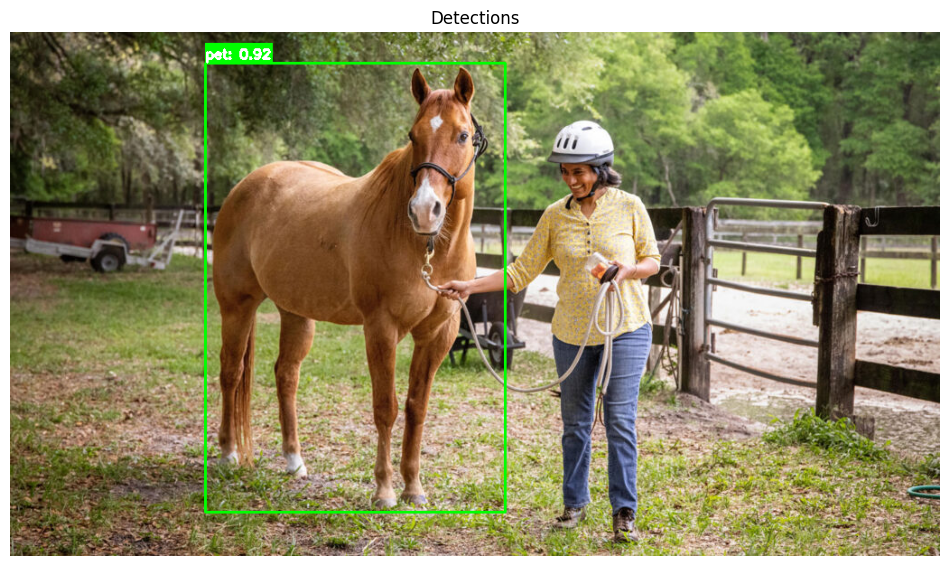

In [28]:
# Initialize the detector with low confidence to catch more weak detections
detector = ObjectDetector(
    model_path='yolo_training/custom_detection_augmented/weights/best.pt',
    conf_threshold=0.2,
    iou_threshold=0.3
)

# Run inference on the target image
image_path = 'test_image.jpg'  # change this if needed
output_path = 'test_image_result.jpg'

# Run and visualize
annotated_img, stats = run_single_image(
    detector,
    image_path=image_path,
    output_path=output_path,
    show=True
)


Loaded model: yolo_training/custom_detection_baseline/weights/best.pt on cuda

Running inference on: test_image.jpg

0: 384x640 1 pet, 20.1ms
Speed: 1.5ms preprocess, 20.1ms inference, 2.7ms postprocess per image at shape (1, 3, 384, 640)

Results:
  Inference time: 0.240 sec | FPS: 4.2
  Total detections: 1
  Persons: 0 | Pets: 1
  Avg confidence: 0.974
  1. pet - conf: 0.97, area: 148863.1

Saved result to: test_image_result_1.jpg


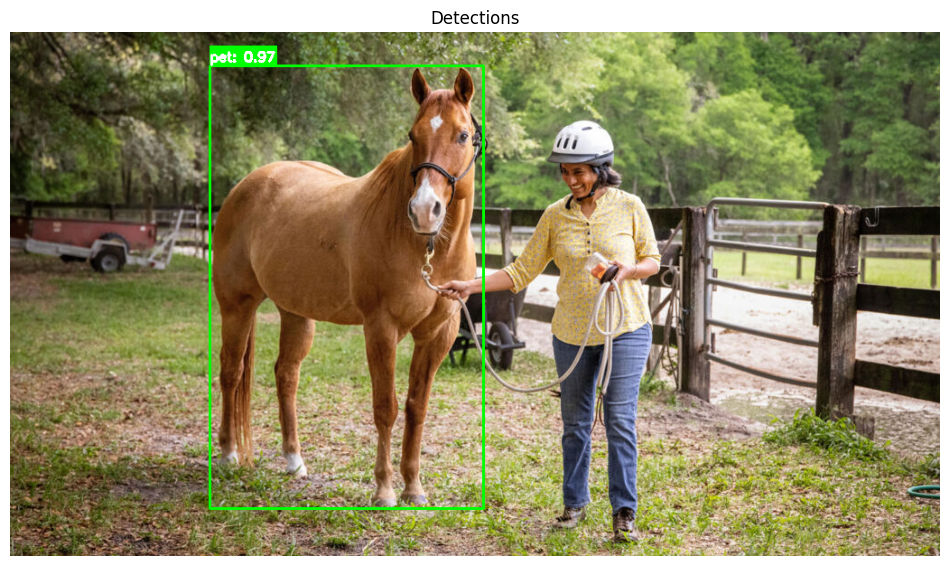

(array([[[ 22,  36,  35],
         [ 20,  35,  37],
         [ 23,  44,  45],
         ...,
         [ 39,  63,  51],
         [ 39,  63,  51],
         [ 39,  63,  51]],
 
        [[ 32,  46,  45],
         [ 28,  43,  45],
         [ 29,  50,  51],
         ...,
         [ 37,  61,  49],
         [ 36,  60,  48],
         [ 36,  60,  48]],
 
        [[ 36,  52,  51],
         [ 33,  48,  50],
         [ 32,  52,  53],
         ...,
         [ 35,  61,  48],
         [ 34,  60,  47],
         [ 33,  59,  46]],
 
        ...,
 
        [[ 66,  99, 114],
         [ 71, 105, 111],
         [ 68, 105, 103],
         ...,
         [159, 168, 188],
         [160, 170, 188],
         [118, 132, 150]],
 
        [[ 37,  70,  85],
         [ 45,  79,  85],
         [ 52,  88,  88],
         ...,
         [172, 181, 201],
         [132, 142, 160],
         [ 46,  60,  78]],
 
        [[ 22,  56,  69],
         [ 38,  72,  78],
         [ 51,  87,  87],
         ...,
         [185, 194, 214],
  

In [29]:
# Initialize model (adjust path as needed)
detector = ObjectDetector(
    model_path='yolo_training/custom_detection_baseline/weights/best.pt',
    conf_threshold=0.2,
    iou_threshold=0.3
)

# Run on a test image
image_path = 'test_image.jpg'
output_path = 'test_image_result_1.jpg'

run_single_image(detector, image_path, output_path=output_path, show=True)


Both classes not detected in the image.
